# Stock 3: the clue that is out of range

Stock 3 has a test row with one clue (`x8`) far outside anything seen in training. The question is: **does that matter?** We'll test 10 different kinds of model and find the one we can trust most.

### The plan

| Part | What we do |
|---|---|
| 1 | Load and check the data |
| 2 | Look at the data: which clues move the price, and how |
| 3 | Test 10 different kinds of model, fairly |
| 4 | Remove the useless clues and test again |
| 5 | Pick the most reliable model and look inside it |
| 6 | Measure how sure we are |
| 7 | Make a quote and a trading plan |

### Words used in this notebook

| Word | Meaning |
|---|---|
| **Clue** (= feature) | One column of the data, `x1` to `x10`. |
| **Row** | One example: 10 clue values and a price. |
| **CV RMSE** | How many pounds a model is wrong by, on average, on rows it hasn't seen. Smaller is better. |
| **Decoy** | A clue that looks important (because it's strange in the test row) but has no effect on the price. |
| **Noise** | The random part of the price that no model can predict. |
| **std** (standard deviation) | The typical size of a spread or an error. |

---
# Part 1: Load and check the data

### Step 1.1: Load the tools

**What this cell does:** loads the libraries we need.
* `pandas` / `numpy`: tables and maths
* `matplotlib`: charts
* `sklearn`: the models and the fair-test tools
* `xgboost` / `lightgbm`: two extra tree-based models

In [1]:
import warnings
warnings.filterwarnings("ignore")          # hide harmless library warnings so the output stays readable

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, SplineTransformer, FunctionTransformer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, cross_val_score, cross_val_predict
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

print("All tools loaded.")

All tools loaded.


### Step 1.2: Open the data files

**What this cell does:** reads the training file (rows with prices) and the test file (the one row we must price), and makes a list of the clue columns.

In [2]:
DATA_DIR = Path("../datasets")     # the data folder is one level up from this notebook
if not DATA_DIR.exists():          # in case the notebook was started from the main folder instead
    DATA_DIR = Path("datasets")

train = pd.read_csv(DATA_DIR / "stock_3_train.csv")   # the examples we learn from
test = pd.read_csv(DATA_DIR / "stock_3_test.csv")     # the one row we must price

clue_columns = [c for c in train.columns if c.startswith("x")]   # x1 ... x10

print("Training data:", train.shape[0], "rows")
print("Test data:    ", test.shape[0], "row")
print("Clues:        ", clue_columns)
train.head()

Training data: 40000 rows
Test data:     1 row
Clues:         ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10']


,uid,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,price
0,2955a3118e,0.6135,0.6169,0.3011,0.7794,0.8258,0.1319,0.6429,0.6960,0.1445,0.3996,296.16
1,9e50685d50,0.4476,0.9654,0.4993,0.0892,0.1504,0.3022,0.2001,0.0664,0.3390,0.9031,275.01
2,0eed06d6dd,0.2853,0.0025,0.4360,0.3443,0.6606,0.9433,0.4144,0.1651,0.9104,0.2340,262.06
3,32d6fec525,0.9450,0.0257,0.6846,0.0795,0.5985,0.0982,0.8319,0.1238,0.3463,0.3126,265.49
4,ba1f40968d,0.3221,0.3863,0.0975,0.5214,0.9299,0.0747,0.3178,0.2085,0.7865,0.1918,283.92


**How to read the output:** **40,000 rows** and **10 clues**. That's a lot of data, so the models will be able to learn the shapes well.

### Step 1.3: Quick health check

**What this cell does:** counts empty cells and repeated rows (we want zeros), and summarises the price.

In [3]:
print("Empty cells in train:", train.isna().sum().sum())
print("Empty cells in test: ", test.isna().sum().sum())
print("Repeated rows in train:", train[clue_columns].duplicated().sum())
train["price"].describe().round(2)

Empty cells in train: 0
Empty cells in test:  0
Repeated rows in train: 0


count    40000.00
mean       278.86
std         10.22
min        246.41
25%        271.58
50%        278.82
75%        286.02
max        313.87
Name: price, dtype: float64

**How to read the output:** no empty cells and no repeated rows. Prices average about **£279**, and most are within about £10 of that.

> **✅ Checkpoint.** Clean data: 40,000 rows, 10 clues.

---
# Part 2: Look at the data

### Step 2.1: What do the clues look like?

**What this cell does:** shows the smallest, largest, average and typical spread of each clue.

In [4]:
train[clue_columns].describe().T[["min", "max", "mean", "std"]].round(2)

,min,max,mean,std
x1,0.0,1.0,0.5,0.29
x2,0.0,1.0,0.5,0.29
x3,0.0,1.0,0.5,0.29
x4,0.0,1.0,0.5,0.29
x5,0.0,1.0,0.5,0.29
x6,0.0,1.0,0.5,0.29
x7,0.0,1.0,0.5,0.29
x8,0.0,1.0,0.5,0.29
x9,0.0,1.0,0.5,0.29
x10,0.0,1.0,0.5,0.29


**How to read the output:** every clue goes from **0 to 1**, with an average of 0.5. They behave like random numbers between 0 and 1.

### Step 2.2: Is the test row normal?

**What this cell does:** for each clue, puts the test value next to the smallest and largest training values, and checks if it's inside that range.

In [5]:
test_row = test[clue_columns].iloc[0]          # the test row: 10 numbers, one per clue

check = pd.DataFrame({
    "test value": test_row,
    "training min": train[clue_columns].min(),
    "training max": train[clue_columns].max(),
})
check["inside training range?"] = (check["test value"] >= check["training min"]) & (check["test value"] <= check["training max"])
check.round(3)

,test value,training min,training max,inside training range?
x1,0.717,0.0,1.0,True
x2,0.810,0.0,1.0,True
x3,0.117,0.0,1.0,True
x4,0.658,0.0,1.0,True
x5,0.350,0.0,1.0,True
x6,0.437,0.0,1.0,True
x7,0.580,0.0,1.0,True
x8,3.703,0.0,1.0,False
x9,0.209,0.0,1.0,True
x10,0.928,0.0,1.0,True


**How to read the output:** 9 clues are normal. **x8 = 3.70**, while in training x8 never goes above 1.00. It's almost 4 times bigger than anything the models have seen.

**What this cell does:** draws the same thing as a picture. Grey = training values, red = the test value.

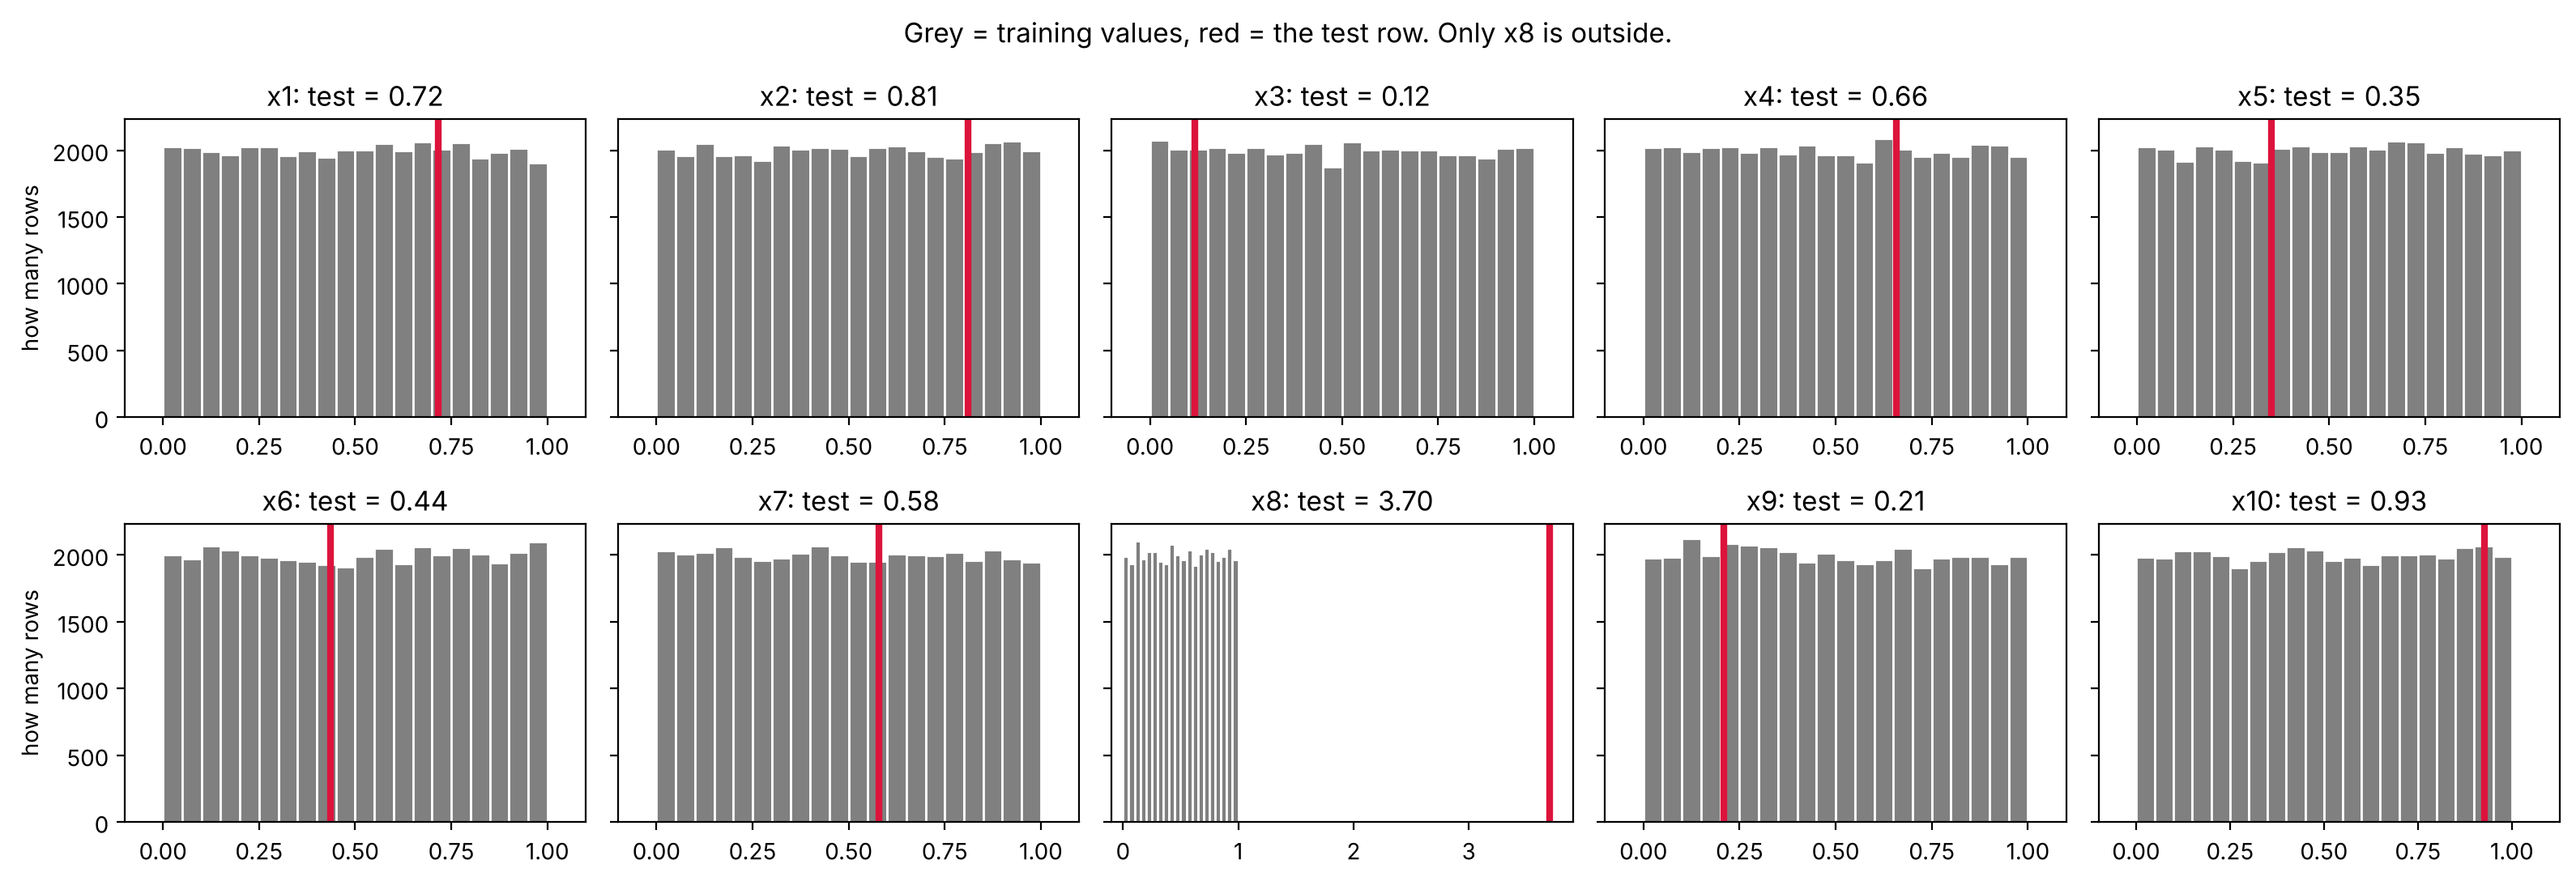

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(16, 5.5), sharey=True)
for ax, clue in zip(axes.ravel(), clue_columns):
    ax.hist(train[clue], bins=20, color="grey", edgecolor="white")    # training values
    ax.axvline(test_row[clue], color="crimson", linewidth=3)          # test value
    ax.set_xlim(-0.1, max(1.1, test_row[clue] + 0.2))
    ax.set_title(f"{clue}: test = {test_row[clue]:.2f}")
axes[0, 0].set_ylabel("how many rows"); axes[1, 0].set_ylabel("how many rows")
fig.suptitle("Grey = training values, red = the test row. Only x8 is outside.")
plt.tight_layout()
plt.show()

**How to read the output:** in every chart except x8, the red line sits inside the grey bars. For x8 it's far to the right.

So the big question is: **does x8 affect the price?** If it does, nobody can know what happens at 3.70. If it doesn't, we can simply ignore it.

### Step 2.3: Which clues move the price, and how?

**What this cell does:** for each clue, it cuts the values into 10 equal slices (0–0.1, 0.1–0.2, …, 0.9–1), works out the **average price in each slice**, and draws a line through those averages.

* **Flat line:** the clue doesn't affect the price.
* **Line going up or down, or curving:** the clue matters, and the line shows the shape of its effect.

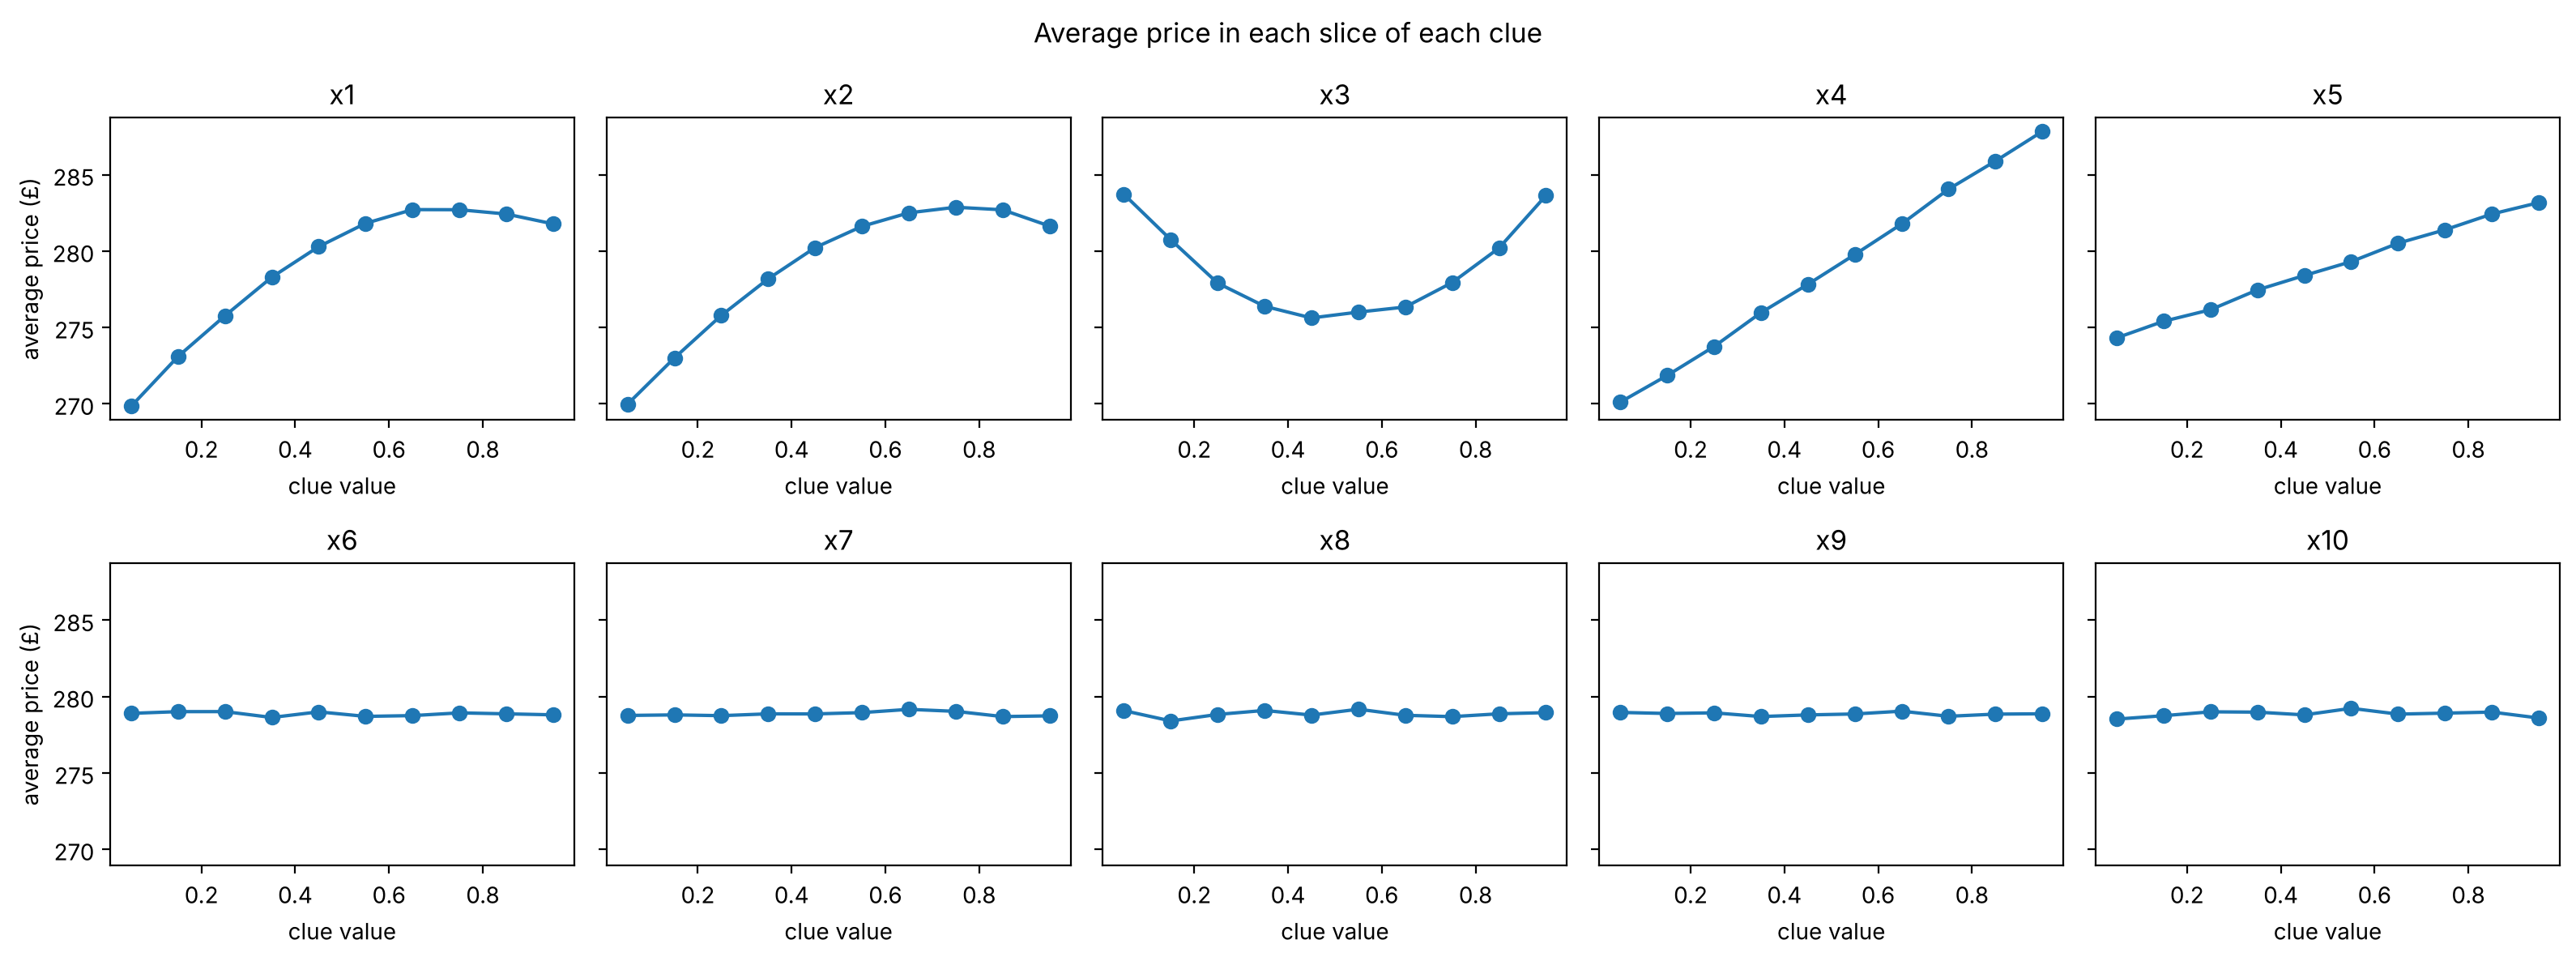

,how much the average price moves (£)
x1,12.88
x2,12.90
x3,8.10
x4,17.72
x5,8.85
x6,0.38
x7,0.47
x8,0.77
x9,0.35
x10,0.71


In [7]:
slices = np.linspace(0, 1, 11)                  # slice edges: 0, 0.1, 0.2, ..., 1
centres = (slices[:-1] + slices[1:]) / 2         # middle of each slice, used for the x-axis

effect_size = {}
fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharey=True)
for ax, clue in zip(axes.ravel(), clue_columns):
    slice_of_row = pd.cut(train[clue], slices, include_lowest=True)          # which slice each row falls into
    avg_price = train.groupby(slice_of_row, observed=True)["price"].mean()   # average price in each slice
    effect_size[clue] = avg_price.max() - avg_price.min()                    # how much the average moves
    ax.plot(centres, avg_price.values, marker="o")
    ax.set_title(clue)
    ax.set_xlabel("clue value")
axes[0, 0].set_ylabel("average price (£)"); axes[1, 0].set_ylabel("average price (£)")
fig.suptitle("Average price in each slice of each clue")
plt.tight_layout()
plt.show()

pd.Series(effect_size).round(2).to_frame("how much the average price moves (£)")

**How to read the output**

| Clue | Shape | Effect |
|---|---|---|
| x1, x2 | Goes up, then levels off | about £13 |
| x3 | **U-shape**: high at both ends, low in the middle | about £8 |
| x4 | Straight line up | about £18 |
| x5 | Straight line up | about £9 |
| **x6–x10** | **Flat** | under £1 (just random wobble) |

**x8 is flat. It has no effect on the price.** The clue that looks scary in the test row is a **decoy**.

### Step 2.4: x1 and x2 work as a team

x1 and x2 have the same shape, which is a hint that they work together. **What this cell does:** multiplies them (x1 × x2) and draws the average price for slices of that product.

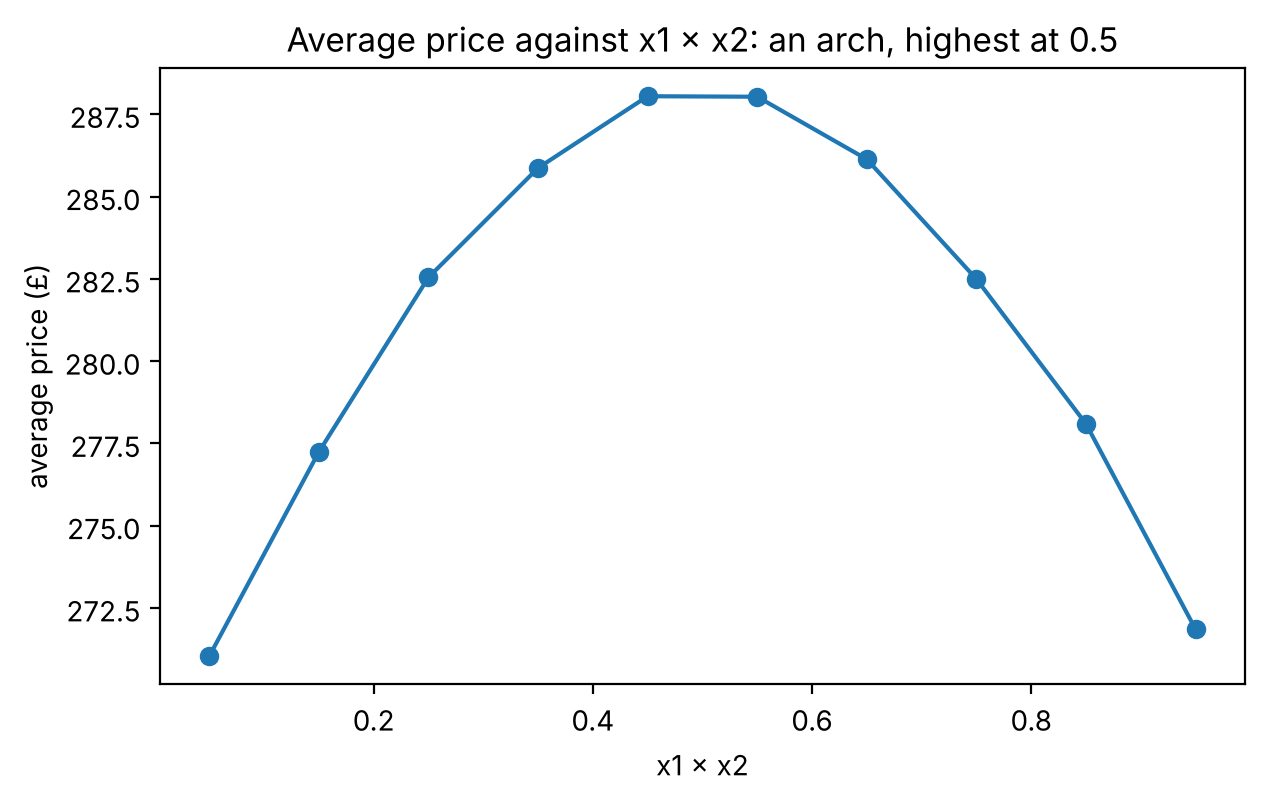

In [8]:
team = train["x1"] * train["x2"]                                      # x1 times x2 for every row
slice_of_row = pd.cut(team, slices, include_lowest=True)
avg_price = train.groupby(slice_of_row, observed=True)["price"].mean()

plt.figure(figsize=(7, 4))
plt.plot(centres, avg_price.values, marker="o")
plt.xlabel("x1 × x2"); plt.ylabel("average price (£)")
plt.title("Average price against x1 × x2: an arch, highest at 0.5")
plt.show()

**How to read the output:** the price rises, peaks when **x1 × x2 ≈ 0.5**, then falls back to the same level at 1. It's a symmetric **arch**, like a rainbow.

The maths shape for an arch like this is **sin(π × value)**: 0 at 0, highest at 0.5, back to 0 at 1. We'll use it in Part 3.

The same idea works for x3's U-shape: "how far x3 is from the middle (0.5), squared", written **(x3 − 0.5)²**. It's 0 in the middle and biggest at both ends.

> **✅ Checkpoint.** Only x1–x5 matter. x8, the out-of-range clue, is a **decoy**. The effects are **curved** (an arch and a U), so a straight-line model won't fit well.

---
# Part 3: Test 10 different kinds of model

### Step 3.1: The fair-test setup

**What this cell does:**
* splits the data into clues (`X`) and prices (`y`)
* makes a **copy of the test row with x8 changed to 0.5**, a normal value (used in Step 3.2)
* sets up **5-fold cross-validation**: cut the data into 5 parts, train on 4 and test on the 5th, 5 times. With 40,000 rows, one round is enough.

In [9]:
X = train[clue_columns]          # the clues
y = train["price"]               # the answers
X_test = test[clue_columns]      # the test row

X_test_x8_normal = X_test.copy()
X_test_x8_normal["x8"] = 0.5     # the same test row, but with a normal x8

cv = KFold(n_splits=5, shuffle=True, random_state=0)    # 5 fair tests

### Step 3.2: The decoy check

We know x8 has no effect. So a reliable model should give **the same price** whether x8 is 3.70 or 0.5.

For every model we'll price the test row twice: as it is (x8 = 3.70) and with x8 = 0.5. The difference shows **how much the model is fooled by the decoy**. A good model is fooled by £0.

### Step 3.3: Turn the shapes into new clues

**What this cell does:** builds 4 new clues from the shapes we found in Part 2. A simple straight-line model can then use them. It's like translating the curves into straight lines.

In [10]:
def make_shape_clues(data):
    # turn the shapes we saw in Part 2 into 4 new clues
    return pd.DataFrame({
        "arch_x1x2": np.sin(np.pi * data["x1"] * data["x2"]),   # arch: highest when x1 × x2 = 0.5
        "x3_from_middle": (data["x3"] - 0.5) ** 2,               # U-shape: distance of x3 from 0.5, squared
        "x4": data["x4"],                                        # straight line
        "x5": data["x5"],                                        # straight line
    })

make_shape_clues(train).head()

,arch_x1x2,x3_from_middle,x4,x5
0,0.927994,3.956121e-02,0.7794,0.8258
1,0.977343,4.900000e-07,0.0892,0.1504
2,0.002241,4.096000e-03,0.3443,0.6606
3,0.076224,3.407716e-02,0.0795,0.5985
4,0.381020,1.620062e-01,0.5214,0.9299


**How to read the output:** each row now has 4 shape clues. Notice that **x6–x10 aren't used at all**, so this model can't be fooled by x8.

### Step 3.4: The 10 models

We test one or two models from every main family:

| Family | Model | How it works, in one line |
|---|---|---|
| Straight line | Linear regression | Best straight line through all 10 clues |
| Curves | Polynomial + Ridge | Adds squares, cubes and products of clues (x1², x1·x2, x8³, …), then fits a line |
| Curves | Splines + Ridge | Bends a flexible ruler along each clue separately |
| Distance | KNN | Finds the 10–60 most similar training rows and averages their prices |
| Trees | Random forest | Hundreds of decision trees, averaged |
| Trees | HistGB | Trees built one after another, each fixing the last one's errors |
| Trees | XGBoost | Same idea as HistGB, with more settings |
| Trees | LightGBM | Same idea as HistGB, with more settings |
| Neural network | MLP | Layers of small "neurons" that learn any shape |
| Hand-made | Shape clues + Linear | Our 4 shape clues from Step 3.3, then a straight line |

**What this cell does:** lists each model with the settings to try. Each model sits in a **Pipeline**, so steps like scaling are learned from the training part only.

In [11]:
grid_models = {
    "Linear regression": (
        Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
        {}),
    "Polynomial + Ridge": (
        Pipeline([("poly", PolynomialFeatures()), ("scaler", StandardScaler()), ("model", Ridge())]),
        {"poly__degree": [2, 3],                     # squares only, or squares and cubes
         "model__alpha": [0.1, 10]}),                # how hard the weights are shrunk
    "Splines + Ridge": (
        Pipeline([("spline", SplineTransformer()), ("model", Ridge())]),
        {"spline__n_knots": [5, 10],                 # how many bend points along each clue
         "model__alpha": [0.1, 10]}),
    "KNN": (
        Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor())]),
        {"model__n_neighbors": [10, 30, 60]}),       # how many similar rows to average
    "Random forest": (
        Pipeline([("model", RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=1))]),
        {"model__min_samples_leaf": [5, 20],         # fewest rows at the end of a branch
         "model__max_features": [0.5, 1.0]}),        # share of clues each split may look at
    "HistGB": (
        Pipeline([("model", HistGradientBoostingRegressor(max_iter=500, random_state=0))]),
        {"model__max_depth": [3, None],              # tree size (None = no limit)
         "model__learning_rate": [0.05, 0.1]}),      # how big a correction each new tree makes
    "Neural network (MLP)": (
        Pipeline([("scaler", StandardScaler()),
                  ("model", MLPRegressor(max_iter=300, early_stopping=True, random_state=0))]),
        {"model__hidden_layer_sizes": [(64, 64), (128, 64)],   # neurons in each layer
         "model__alpha": [0.0001, 0.01]}),                     # penalty that keeps the weights small
    "Shape clues + Linear": (
        Pipeline([("shapes", FunctionTransformer(make_shape_clues)), ("model", LinearRegression())]),
        {}),
}

random_models = {
    "XGBoost": (
        Pipeline([("model", XGBRegressor(random_state=0, n_jobs=1))]),
        {"model__n_estimators": [300, 600, 1000],     # how many trees
         "model__learning_rate": [0.03, 0.05, 0.1],   # how big a correction each new tree makes
         "model__max_depth": [3, 4, 6],               # how big each tree can grow
         "model__min_child_weight": [1, 10],          # fewest rows at the end of a branch
         "model__subsample": [0.8, 1.0],              # share of rows each tree sees
         "model__colsample_bytree": [0.5, 0.8, 1.0],  # share of clues each tree sees
         "model__reg_lambda": [1, 10]}),              # penalty that keeps the effects small
    "LightGBM": (
        Pipeline([("model", LGBMRegressor(random_state=0, n_jobs=1, subsample_freq=1, verbose=-1))]),
        {"model__n_estimators": [300, 600, 1000],
         "model__learning_rate": [0.03, 0.05, 0.1],
         "model__num_leaves": [7, 15, 31],            # how big each tree can grow
         "model__min_child_samples": [20, 50],
         "model__subsample": [0.8, 1.0],
         "model__colsample_bytree": [0.5, 0.8, 1.0],
         "model__reg_lambda": [0, 10]}),
}
print("Models ready:", list(grid_models) + list(random_models))

Models ready: ['Linear regression', 'Polynomial + Ridge', 'Splines + Ridge', 'KNN', 'Random forest', 'HistGB', 'Neural network (MLP)', 'Shape clues + Linear', 'XGBoost', 'LightGBM']


XGBoost and LightGBM have so many settings that trying every combination would take too long. `RandomizedSearchCV` tries **12 random combinations** instead. All the other models use `GridSearchCV`, which tries every combination.

### Step 3.5: Run the contest

**What this cell does:** for each model, it
1. tries the settings with 5-fold cross-validation and keeps the best
2. retrains the best version on all 40,000 rows
3. prices the test row twice (x8 = 3.70, and x8 = 0.5) for the decoy check

It takes a few minutes. You'll see "… done" after each model.

In [12]:
results = []
searches = {}

def record(name, search):
    # save one finished search and its scores
    searches[name] = search
    price = float(np.ravel(search.predict(X_test))[0])                    # x8 = 3.70, as given
    price_x8_normal = float(np.ravel(search.predict(X_test_x8_normal))[0])  # x8 = 0.5
    results.append({
        "model": name,
        "CV RMSE (£)": round(-search.best_score_, 3),
        "test price (£)": round(price, 2),
        "price if x8 normal (£)": round(price_x8_normal, 2),
        "fooled by x8 (£)": round(price - price_x8_normal, 2),
    })
    print(f"{name} done")

for name, (pipe, settings) in grid_models.items():
    search = GridSearchCV(pipe, settings, cv=cv,
                          scoring="neg_root_mean_squared_error",   # sklearn maximises, so RMSE is made negative
                          n_jobs=-1)
    search.fit(X, y)
    record(name, search)

for name, (pipe, settings) in random_models.items():
    search = RandomizedSearchCV(pipe, settings, n_iter=12, cv=cv, random_state=0,
                                scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

results = pd.DataFrame(results).sort_values("CV RMSE (£)").reset_index(drop=True)
results

Linear regression done


Polynomial + Ridge done


Splines + Ridge done


KNN done


Random forest done


HistGB done


Neural network (MLP) done
Shape clues + Linear done


XGBoost done


LightGBM done


,model,CV RMSE (£),test price (£),price if x8 normal (£),fooled by x8 (£)
0,Shape clues + Linear,2.986,291.95,291.95,0.00
1,Polynomial + Ridge,3.062,307.33,291.78,15.55
2,XGBoost,3.062,292.08,292.10,-0.01
3,LightGBM,3.069,292.20,292.19,0.01
4,HistGB,3.105,291.67,291.67,0.00
5,Neural network (MLP),3.135,293.70,291.32,2.38
6,Random forest,3.464,289.79,290.39,-0.60
7,Splines + Ridge,4.025,290.92,290.95,-0.03
8,KNN,4.432,289.02,290.08,-1.06
9,Linear regression,5.726,287.86,287.68,0.18


**How to read the output**

| Column | Meaning |
|---|---|
| CV RMSE | How wrong the model is on rows it hasn't seen. Smaller is better. |
| test price | The model's price for the real test row (x8 = 3.70) |
| price if x8 normal | Its price for the same row with x8 = 0.5 |
| fooled by x8 | The difference. **Should be about £0**, because x8 has no effect. |

**What this cell does:** shows the best settings each model found, in case you want them.

In [13]:
for name, search in searches.items():
    print(f"{name}: {search.best_params_}")

Linear regression: {}
Polynomial + Ridge: {'model__alpha': 0.1, 'poly__degree': 3}
Splines + Ridge: {'model__alpha': 0.1, 'spline__n_knots': 5}
KNN: {'model__n_neighbors': 10}
Random forest: {'model__max_features': 1.0, 'model__min_samples_leaf': 5}
HistGB: {'model__learning_rate': 0.05, 'model__max_depth': 3}
Neural network (MLP): {'model__alpha': 0.01, 'model__hidden_layer_sizes': (64, 64)}
Shape clues + Linear: {}
XGBoost: {'model__subsample': 0.8, 'model__reg_lambda': 1, 'model__n_estimators': 1000, 'model__min_child_weight': 10, 'model__max_depth': 4, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}
LightGBM: {'model__subsample': 0.8, 'model__reg_lambda': 0, 'model__num_leaves': 7, 'model__n_estimators': 1000, 'model__min_child_samples': 20, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.8}


### Step 3.6: Accuracy and the decoy check, side by side

**What this cell does:** draws two bar charts. Left: CV RMSE. Right: how much each model is fooled by x8. Red bars mean fooled by more than 50p.

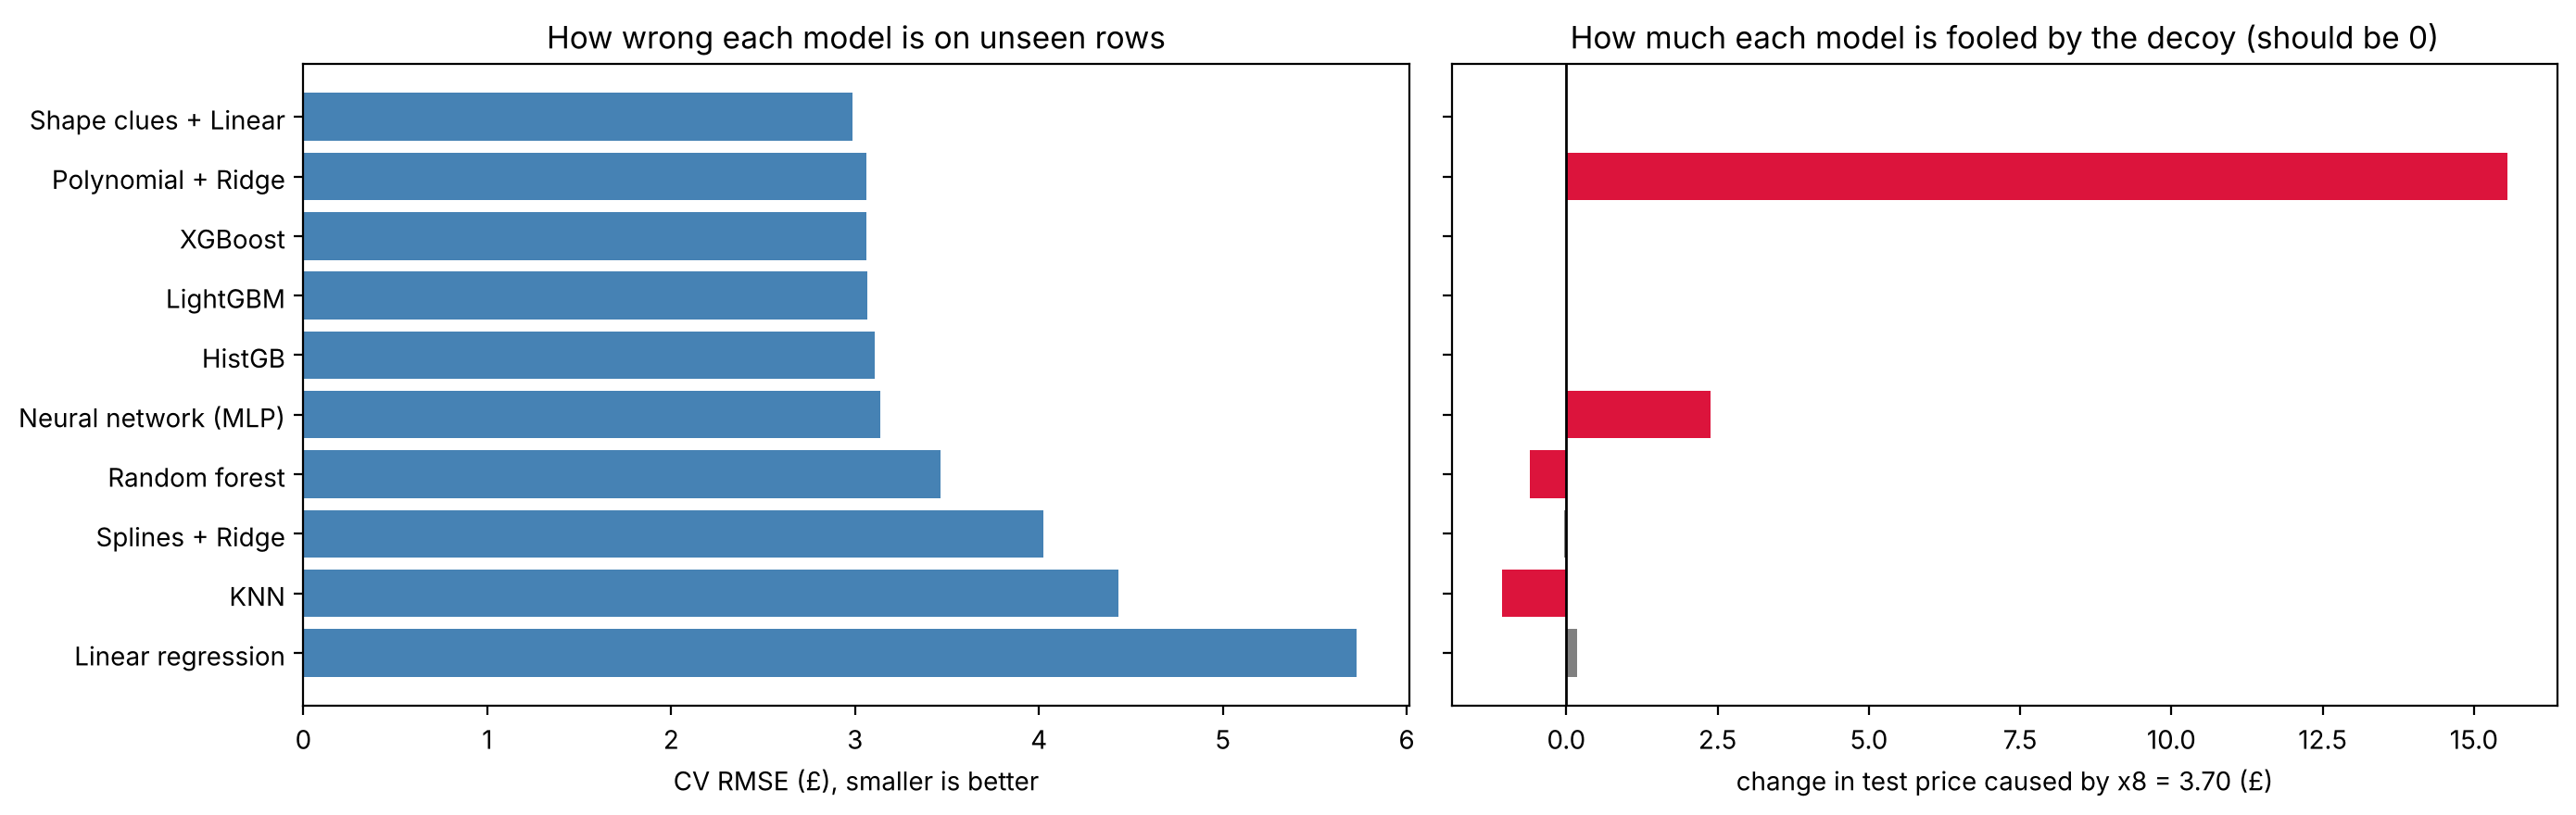

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

axes[0].barh(results["model"], results["CV RMSE (£)"], color="steelblue")
axes[0].set_xlabel("CV RMSE (£), smaller is better")
axes[0].set_title("How wrong each model is on unseen rows")
axes[0].invert_yaxis()                                     # best model at the top

fooled = results["fooled by x8 (£)"]
axes[1].barh(results["model"], fooled, color=["crimson" if abs(v) > 0.5 else "grey" for v in fooled])
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_xlabel("change in test price caused by x8 = 3.70 (£)")
axes[1].set_title("How much each model is fooled by the decoy (should be 0)")

plt.tight_layout()
plt.show()

### Step 3.7: Slide x8 from 0 to 4

**What this cell does:** keeps the test row the same but changes x8 step by step from 0 to 4, and asks every model for a price at each step.

A reliable model draws a **flat line**, because x8 doesn't matter. The grey area is the range of x8 seen in training, and the dashed line is the test row's x8.

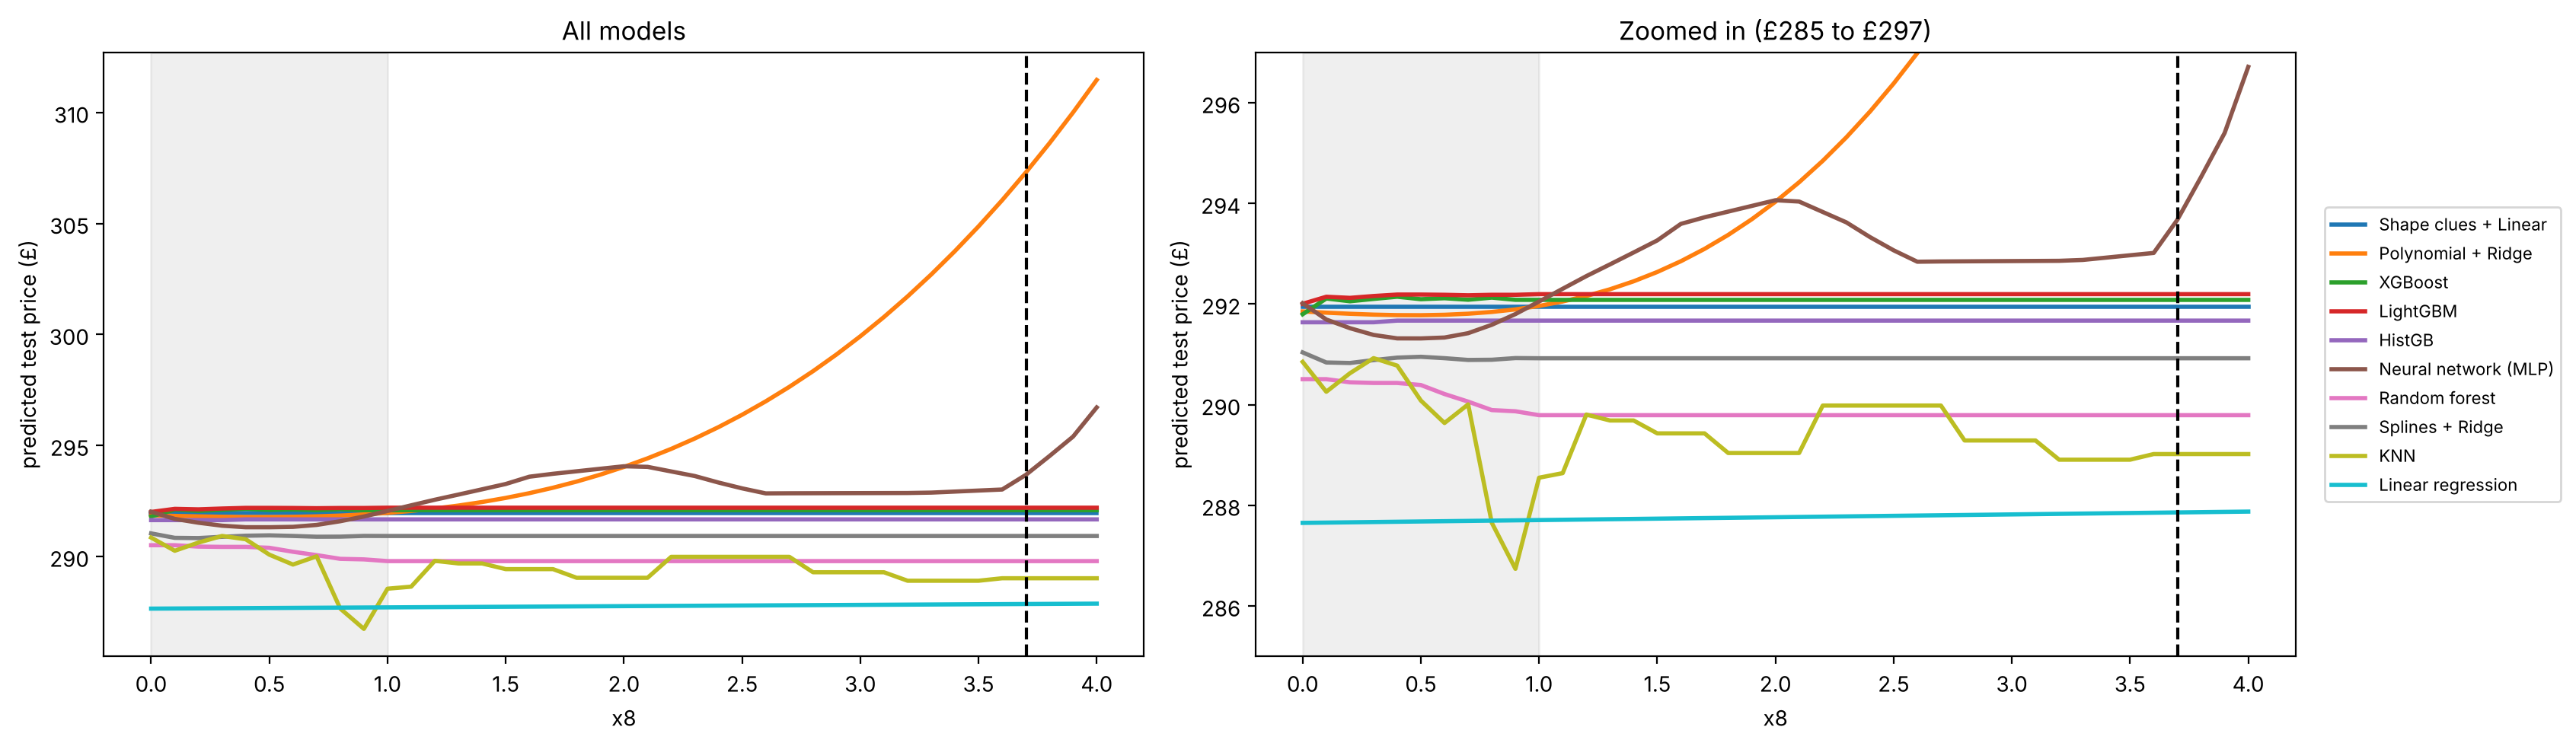

In [15]:
x8_values = np.linspace(0, 4, 41)                             # 0, 0.1, 0.2, ..., 4
rows = pd.concat([X_test] * len(x8_values), ignore_index=True) # 41 copies of the test row
rows["x8"] = x8_values                                         # each copy gets a different x8

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for name in results["model"]:
    prices = np.ravel(searches[name].predict(rows))
    for ax in axes:
        ax.plot(x8_values, prices, label=name, linewidth=2)
for ax in axes:
    ax.axvspan(0, 1, color="grey", alpha=0.12)
    ax.axvline(test_row["x8"], color="black", linestyle="--")
    ax.set_xlabel("x8"); ax.set_ylabel("predicted test price (£)")
axes[0].set_title("All models")
axes[1].set_ylim(285, 297)
axes[1].set_title("Zoomed in (£285 to £297)")
axes[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))   # legend outside the chart
plt.tight_layout()
plt.show()

**How to read Steps 3.5 to 3.7**

* **Shape clues + Linear is the most accurate** (£2.99) and isn't fooled at all, because it never looks at x8.
* **XGBoost, LightGBM and HistGB** are almost as accurate (£3.06–3.11) and aren't fooled. A tree can't see past the largest x8 it was trained on, so it treats 3.70 the same as 1.00. Since x8 has no effect, that's harmless.
* **Polynomial + Ridge is the trap.** Its CV RMSE is excellent (£3.06), but x8 = 3.70 pushes its price up by about **£15**. It contains terms like x8³ = 3.70³ ≈ 51, and tiny weights it learned by chance get multiplied by those big numbers. In the slide chart its line shoots upwards after x8 = 1.
* **The neural network** is fooled by about **£2.40**. It has never seen x8 above 1, so its line bends in a way nobody can predict.
* **KNN** looks for "similar rows", and x8 = 3.70 makes it pick rows with a large x8 instead of rows that are similar on x1–x5. It's fooled by about £1, and it's also not very accurate.
* **Random forest** moves by about 60p. Its deep trees learned small random wiggles in x8 between 0 and 1 (its line drifts down inside the grey area), and the test row lands at the far end of those wiggles.
* **Linear regression** and **splines** aren't fooled, but they're inaccurate (£5.73 and £4.03). A straight line can't follow an arch, and splines treat x1 and x2 separately, so they miss the "team" effect.

**The big lesson:** a good CV RMSE is not enough. CV RMSE only tests rows that look like the training data, and our test row doesn't.

> **✅ Checkpoint.** The most accurate models are the shape-clue model and the boosted trees. Polynomial, the neural network and KNN are fooled by the decoy.

---
# Part 4: Remove the useless clues and test again

x6–x10 have no effect (Step 2.3). If we remove them:
* the models lose nothing, because those clues carry no information
* **the test row becomes completely normal**, since x1–x5 are all inside the training range
* no model can be fooled by x8 any more

**What this cell does:** takes the best version of each model from Part 3, retrains it on **x1–x5 only**, and scores it again with the same 5-fold test. The shape-clue model already uses only x1–x5, so we copy its Part 3 result.

In [16]:
useful_clues = ["x1", "x2", "x3", "x4", "x5"]
models_to_retest = ["Polynomial + Ridge", "KNN", "Random forest", "XGBoost", "LightGBM", "Neural network (MLP)"]

before = results.set_index("model")
retest = []
for name in models_to_retest:
    model = clone(searches[name].best_estimator_)          # same model and best settings, not trained yet
    rmse = -cross_val_score(model, X[useful_clues], y, cv=cv,
                            scoring="neg_root_mean_squared_error", n_jobs=-1).mean()
    model.fit(X[useful_clues], y)
    retest.append({"model": name,
                   "CV RMSE before (£)": before.loc[name, "CV RMSE (£)"],
                   "CV RMSE after (£)": round(rmse, 3),
                   "test price before (£)": before.loc[name, "test price (£)"],
                   "test price after (£)": round(float(model.predict(X_test[useful_clues])[0]), 2)})
    print(f"{name} done")

shape_row = before.loc["Shape clues + Linear"]
retest.append({"model": "Shape clues + Linear",
               "CV RMSE before (£)": shape_row["CV RMSE (£)"], "CV RMSE after (£)": shape_row["CV RMSE (£)"],
               "test price before (£)": shape_row["test price (£)"], "test price after (£)": shape_row["test price (£)"]})

retest = pd.DataFrame(retest).sort_values("CV RMSE after (£)").reset_index(drop=True)
retest

Polynomial + Ridge done


KNN done


Random forest done


XGBoost done


LightGBM done


Neural network (MLP) done


,model,CV RMSE before (£),CV RMSE after (£),test price before (£),test price after (£)
0,Shape clues + Linear,2.986,2.986,291.95,291.95
1,XGBoost,3.062,3.047,292.08,292.23
2,LightGBM,3.069,3.049,292.20,292.20
3,Polynomial + Ridge,3.062,3.050,307.33,291.97
4,Neural network (MLP),3.135,3.109,293.70,292.68
5,KNN,4.432,3.356,289.02,291.61
6,Random forest,3.464,3.383,289.79,290.93


**What this cell does:** draws every model's test price before (grey) and after (red) removing x6–x10.

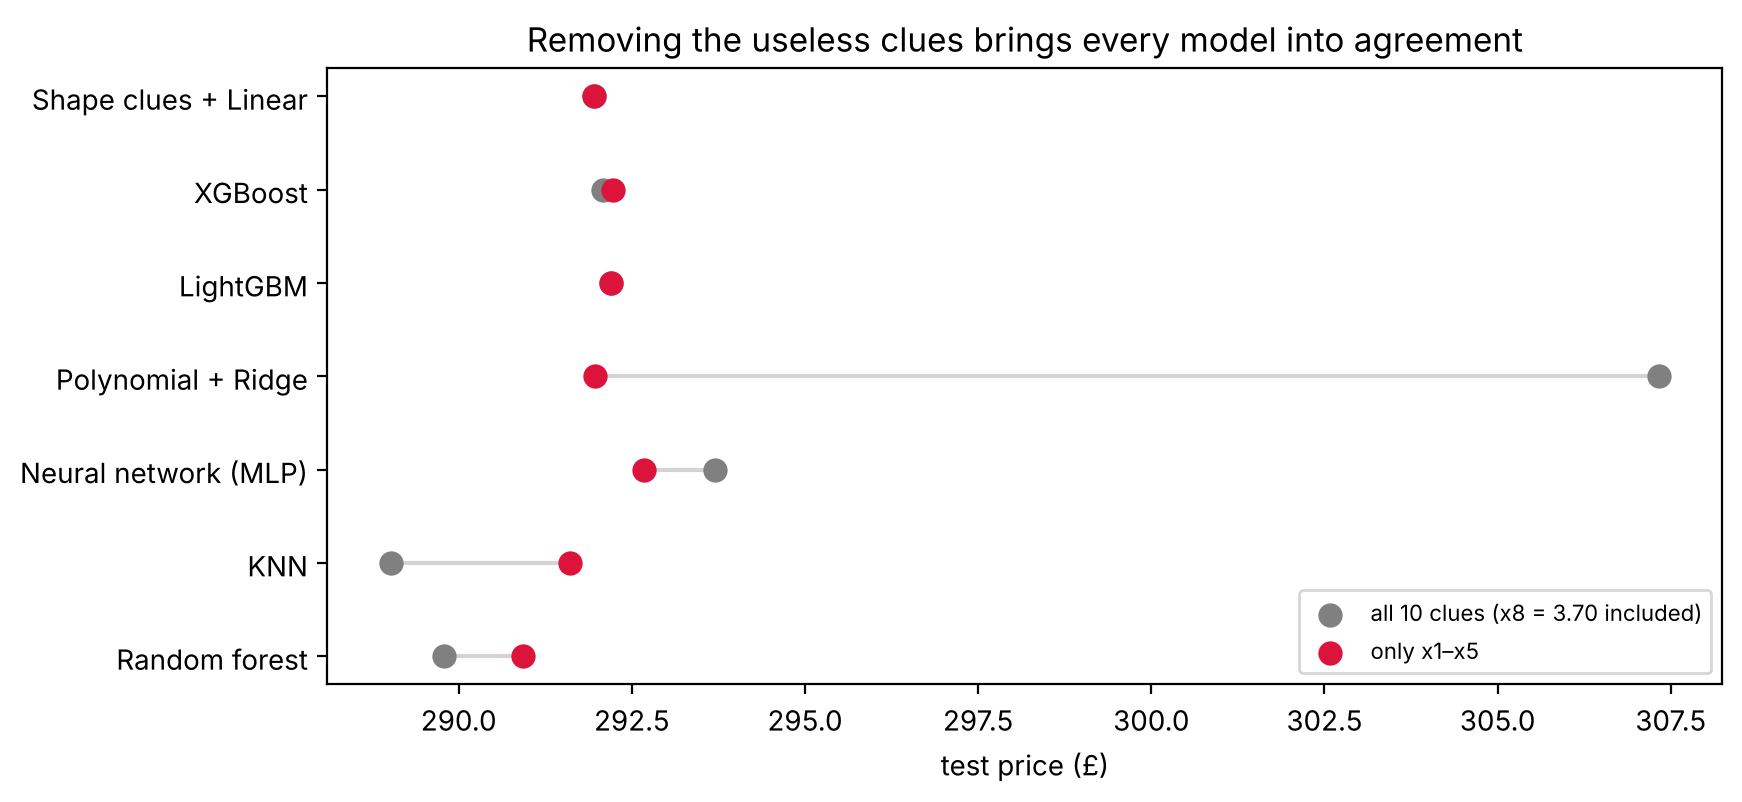

In [17]:
plt.figure(figsize=(9, 4))
ypos = np.arange(len(retest))
plt.scatter(retest["test price before (£)"], ypos, color="grey", s=60, label="all 10 clues (x8 = 3.70 included)")
plt.scatter(retest["test price after (£)"], ypos, color="crimson", s=60, label="only x1–x5")
for i in ypos:
    plt.plot([retest.loc[i, "test price before (£)"], retest.loc[i, "test price after (£)"]], [i, i],
             color="lightgrey", zorder=0)
plt.yticks(ypos, retest["model"])
plt.gca().invert_yaxis()
plt.xlabel("test price (£)")
plt.title("Removing the useless clues brings every model into agreement")
plt.legend(loc="lower right", fontsize=8)
plt.show()

**How to read the output**

* **Every model got more accurate or stayed the same.** KNN improved the most (£4.43 → £3.36), because it no longer gets distracted by 5 useless clues.
* **The polynomial model's price fell from about £307 to £292.** The decoy was the whole problem.
* **All models now agree**, between about £291 and £293.

> **✅ Checkpoint.** Removing useless clues is free accuracy, and it makes the test row normal. **Always check which clues matter before trusting a model on a strange row.**

---
# Part 5: Pick the most reliable model

### Step 5.1: The scorecard

| Model | Accuracy (CV RMSE) | Fooled by x8? | Easy to explain? |
|---|---|---|---|
| **Shape clues + Linear** | **£2.99, the best** | **No, never uses x8** | **Yes: 5 numbers** |
| XGBoost / LightGBM | £3.05–3.07 | No | No (1,000 trees) |
| Polynomial + Ridge | £3.05–3.06 | **Yes, about £15**, unless x6–x10 are removed | Partly |
| Neural network | £3.11–3.14 | **Yes, about £2.40**, unless x6–x10 are removed | No |
| Random forest, KNN | £3.36–4.43 | A little | No |
| Linear, Splines | £4.03–5.73 | No | Yes, but inaccurate |

**Winner: Shape clues + Linear.** It's the most accurate, it can't be fooled by x8, and it's simple enough to check by hand.

**Backup: XGBoost or LightGBM on x1–x5.** Use these when you can't find the shapes yourself. They get within 6p of the winner automatically.

### Step 5.2: Train the final model and look inside

**What this cell does:** trains the winner on all 40,000 rows, prices the test row, and shows the sum step by step (start + weight × shape clue).

In [18]:
final_model = Pipeline([("shapes", FunctionTransformer(make_shape_clues)), ("model", LinearRegression())])
final_model.fit(X, y)
prediction = float(final_model.predict(X_test)[0])

shape_names = ["arch_x1x2", "x3_from_middle", "x4", "x5"]
weights = final_model.named_steps["model"].coef_
start = final_model.named_steps["model"].intercept_
test_shapes = make_shape_clues(X_test).iloc[0]

print(f"start{'':30}{start:8.2f}")
total = start
for name, weight in zip(shape_names, weights):
    total += weight * test_shapes[name]
    print(f"+ {weight:6.2f} × {name:15s} ({test_shapes[name]:5.3f})   {weight * test_shapes[name]:+8.2f}")
print(f"{'= prediction':35}{total:8.2f}")

start                                249.96
+  20.06 × arch_x1x2       (0.968)     +19.42
+  40.01 × x3_from_middle  (0.147)      +5.87
+  20.04 × x4              (0.658)     +13.18
+  10.07 × x5              (0.350)      +3.52
= prediction                         291.95


**How to read the output**

* **Start ≈ £250**: the price when every shape clue is 0 (x1 × x2 = 0, x3 = 0.5, x4 = 0, x5 = 0). That's the lowest base price.
* **Weights:** the arch is worth up to **£20**, x3's distance from the middle up to **£40 × 0.25 = £10**, x4 up to **£20** and x5 up to **£10**.
* The weights come out as very round numbers (20, 40, 20, 10). That's a strong sign we found the real formula behind the data.
* **Prediction: £291.95.**

### Step 5.3: See the data and our lines

**What this cell does:** one chart per shape clue. For each one, the effect of the other 3 shape clues is **removed** from the price, so we see only this clue's effect.
* **Dots:** 3,000 random training rows (fewer than 40,000, so the chart stays readable)
* **Red line:** our model's line
* **Dashed line:** the test row's value

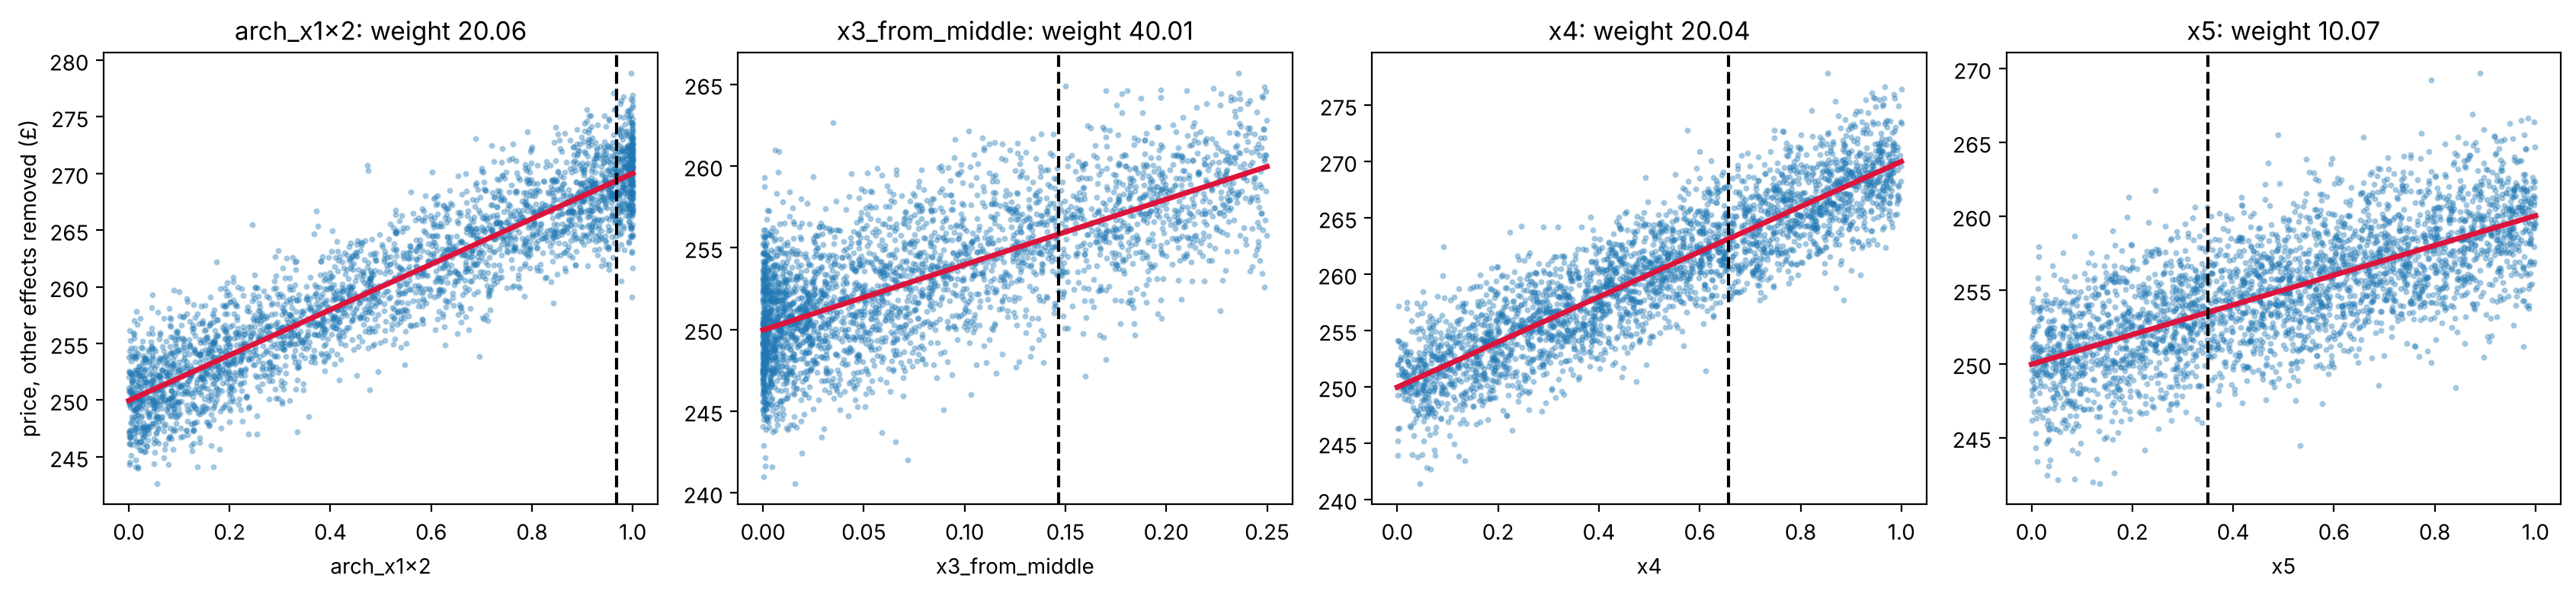

In [19]:
shapes_train = make_shape_clues(X)
sample = shapes_train.sample(3000, random_state=0).index      # 3,000 random rows for a readable chart

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, name, weight in zip(axes, shape_names, weights):
    others = [n for n in shape_names if n != name]
    other_effects = (shapes_train[others] * [weights[shape_names.index(n)] for n in others]).sum(axis=1)
    price_adjusted = y - other_effects                          # price with the other shape effects removed

    ax.scatter(shapes_train.loc[sample, name], price_adjusted[sample], s=4, alpha=0.3)
    xs = np.linspace(shapes_train[name].min(), shapes_train[name].max(), 50)
    ax.plot(xs, start + weight * xs, color="crimson", linewidth=2.5)
    ax.axvline(test_shapes[name], color="black", linestyle="--")
    ax.set_title(f"{name}: weight {weight:.2f}")
    ax.set_xlabel(name)
axes[0].set_ylabel("price, other effects removed (£)")
plt.tight_layout()
plt.show()

**How to read the output:** in every chart the dots follow the red line, so once the shapes are turned into shape clues, everything is a straight line. The dashed test values sit **inside** the data in all 4 charts, so for this model **the test row is completely normal**.

### Step 5.4: Predicted vs actual

**What this cell does:** gets "honest" predictions for every training row with `cross_val_predict` (each row is predicted by a model that didn't see it), then plots predicted against actual for 3,000 random rows. A perfect model would put every dot on the red diagonal.

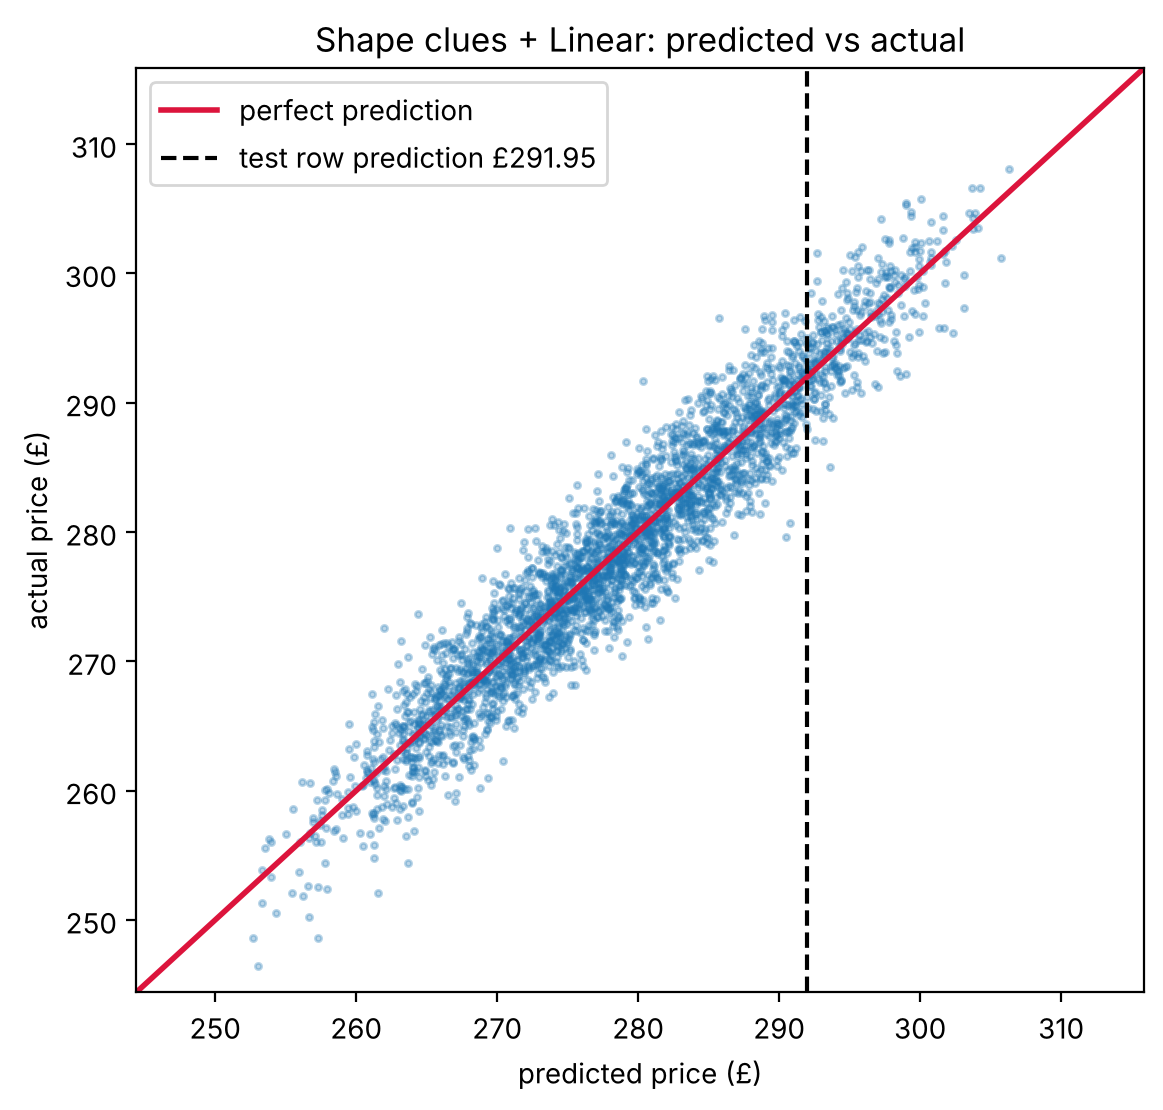

In [20]:
honest_pred = cross_val_predict(final_model, X, y, cv=cv)    # each row predicted by a model that never saw it
errors = y - honest_pred

plt.figure(figsize=(6.5, 6))
plt.scatter(honest_pred[sample], y[sample], s=5, alpha=0.3)
lims = [y.min() - 2, y.max() + 2]
plt.plot(lims, lims, color="crimson", linewidth=2, label="perfect prediction")
plt.axvline(prediction, color="black", linestyle="--", label=f"test row prediction £{prediction:.2f}")
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("predicted price (£)"); plt.ylabel("actual price (£)")
plt.title("Shape clues + Linear: predicted vs actual")
plt.legend(loc="upper left")
plt.show()

**How to read the output:** the dots form a tight band around the diagonal. The band's width is the noise: about ±£3.

### Step 5.5: Is what's left just random noise?

If the leftover errors are pure noise, **no model can do better**, and £2.99 is the best possible score.

**What this cell does:**
1. draws a histogram of the errors
2. counts how many errors fall within ±£3 and ±£6
3. checks whether any clue is still related to the errors

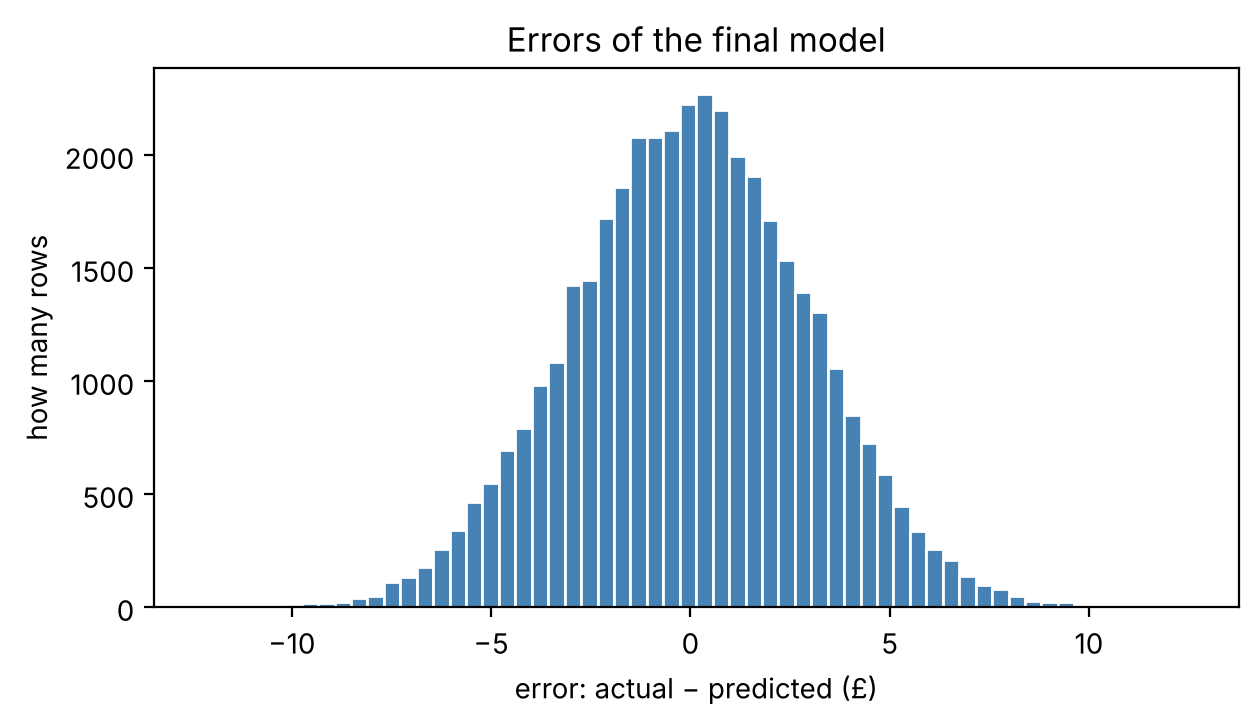

Error std:            £2.99
Errors within ±£3:    68.4%
Errors within ±£6:    95.6%

Correlation of the errors with each clue (0 = no link left):
x1    -0.002
x2     0.005
x3    -0.011
x4    -0.000
x5     0.000
x6     0.000
x7    -0.001
x8     0.006
x9     0.003
x10    0.007


In [21]:
plt.figure(figsize=(7, 3.5))
plt.hist(errors, bins=60, color="steelblue", edgecolor="white")
plt.xlabel("error: actual − predicted (£)"); plt.ylabel("how many rows")
plt.title("Errors of the final model")
plt.show()

print(f"Error std:            £{errors.std():.2f}")
print(f"Errors within ±£3:    {(errors.abs() <= 3).mean():.1%}")
print(f"Errors within ±£6:    {(errors.abs() <= 6).mean():.1%}")
print("\nCorrelation of the errors with each clue (0 = no link left):")
print(X.corrwith(errors).round(3).to_string())

**How to read the output**

* The errors form a **bell shape**, centred on 0, with a std of about **£3**.
* About **68%** are within ±£3 and about **96%** within ±£6. That's exactly what pure, bell-shaped noise looks like.
* No clue is linked to the errors any more (all correlations are about 0). There's nothing left for any model to learn.

So **£3 is the noise floor**. That's why all the good models stopped at about £3.0–3.1, and why fancier models can't help.

> **✅ Checkpoint.** Final model: **Shape clues + Linear**, prediction **£291.95**, error ≈ pure noise of £3.

---
# Part 6: How sure are we?

There are two kinds of uncertainty:

| Kind | Question | Stock 2 | Stock 3 |
|---|---|---|---|
| **Model error** | Did the model learn the right weights? | **Big** (140 rows, extreme test row) | ? |
| **Noise** | How far is the true price from the formula? | £4–5 | £3 |

### Step 6.1: Model error (bootstrap)

**What this cell does:** retrains the final model 200 times, each time on 40,000 rows picked at random (some rows twice, some not at all), and prices the test row each time. The spread tells us how much the model itself could be off.

In [22]:
rng = np.random.default_rng(0)
boot_prices = []
for b in range(200):
    rows_b = rng.integers(0, len(train), len(train))               # 40,000 random rows, some picked twice
    model_b = clone(final_model).fit(X.iloc[rows_b], y.iloc[rows_b])
    boot_prices.append(float(model_b.predict(X_test)[0]))
boot_prices = np.array(boot_prices)

print(f"Average test price over 200 retrains: £{boot_prices.mean():.2f}")
print(f"Spread (std):                         £{boot_prices.std():.2f}")

Average test price over 200 retrains: £291.95
Spread (std):                         £0.03


**How to read the output:** the price moves by only about **£0.03**. With 40,000 rows and a test row that's normal for this model, the model error is tiny.

### Step 6.2: Total uncertainty

The model error (£0.03) is tiny next to the noise (£3), so **the total uncertainty is about £3**:
* about 68% chance the true price is within **£291.95 ± £3** (£288.95 to £294.95)
* about 95% chance it's within **± £6** (£285.95 to £297.95)

### Step 6.3: The one risk we can't measure

The data shows x8 has no effect **between 0 and 1**. Nobody can check whether it suddenly matters above 1, because there's no data there. That would be a strange way to build a dataset, and every reliable model agrees x8 doesn't matter, so we accept this small risk.

> **✅ Checkpoint.** Uncertainty ≈ **£3** (just the noise). That's far smaller than stock 2's £15.

---
# Part 7: Make a quote and a trading plan

### Step 7.1: The central estimate

**What this cell does:** compares our final model with the backup models trained on x1–x5 (Part 4), as a cross-check.

In [23]:
backups = retest.set_index("model")["test price after (£)"].drop("Shape clues + Linear")
centre = prediction

print(f"Final model (Shape clues + Linear): £{centre:.2f}")
print(f"Backup models on x1–x5:             £{backups.min():.2f} to £{backups.max():.2f}")
print(f"Best backups (XGBoost, LightGBM):   £{backups['XGBoost']:.2f}, £{backups['LightGBM']:.2f}")

Final model (Shape clues + Linear): £291.95
Backup models on x1–x5:             £290.93 to £292.68
Best backups (XGBoost, LightGBM):   £292.23, £292.20


**How to read the output:** every backup lands within about £1 of our price, and XGBoost and LightGBM within about 30p. Our centre is **£291.95**.

### Step 7.2: Quote options

Same formula as before: **bid = centre − h** and **ask = centre + h**.

**What this cell does:** prints three quotes, from tight to wide.

In [24]:
for h, meaning in [(1.5, "half the noise: competing to be market maker"),
                   (3.0, "1 std of noise: true price inside about 68% of the time"),
                   (6.0, "2 std of noise: true price inside about 95% of the time")]:
    print(f"h = £{h:<4}  bid £{centre - h:.2f}   ask £{centre + h:.2f}   ({meaning})")

h = £1.5   bid £290.45   ask £293.45   (half the noise: competing to be market maker)
h = £3.0   bid £288.95   ask £294.95   (1 std of noise: true price inside about 68% of the time)
h = £6.0   bid £285.95   ask £297.95   (2 std of noise: true price inside about 95% of the time)


### Step 7.3: Should we try to be market maker on stock 3?

This is the best candidate so far:
* **Our price is as good as it can get.** The only error left is noise, which nobody can predict, so no team can know the true price better than we do.
* **Teams fooled by x8 will trade against us in the wrong direction.** Someone using a polynomial model thinks the price is about £307, so they'll buy from us at our ask. On average, we profit from their mistake.

**The risk:** the noise. Example: 10 teams each buy about £100k worth (about 340 shares each, 3,400 in total) at our ask of £293.45, and the true price comes out 2 std high, at £297.95. We lose £4.50 × 3,400 ≈ **£15,000**. That's painful but survivable, and it's the unlucky case. On average we gain.

**Suggestion:** quote **h = £1.50 (bid £290.45, ask £293.45)** if you want to compete for market maker. Use **h = £3** if you'd rather be a trader.

### Step 7.4: Trading plan (if another team is market maker)

Compare their bid and ask with our centre of **£291.95**, using the noise (£3) as the ruler:

| Market maker's prices | What we do | Size |
|---|---|---|
| **Ask below £286** (more than £6 under our centre) | **Buy** | Big |
| **Bid above £298** (more than £6 over our centre) | **Sell** | Big |
| Ask between £286 and £289 | Buy | Medium |
| Bid between £295 and £298 | Sell | Medium |
| Our centre within about £3 of their prices | Little edge | Minimum 10 shares, on the side our centre leans towards |

**Likely scenarios:**
* Market maker used **polynomial on all clues** (mid about £307) → **sell big**.
* Market maker used **linear regression or KNN on all clues** (mid about £288–289) → **buy**, medium size.
* Market maker used **XGBoost / LightGBM / HistGB** (mid about £292) → no edge, trade the minimum.

---

### Lessons so far

| Stock | Trap | What we did |
|---|---|---|
| 1 | None (warm-up) | Linear regression, quote ±1–2 std |
| 2 | Few rows, extreme test row | Wide quote (±£15), stay a trader |
| 3 | Out-of-range **decoy** clue | Checked it has no effect, removed it, confident quote (±£1.50–3) |

> **✅ Final checkpoint.** Stock 3 price **£291.95 ± £3**. Most reliable model: **Shape clues + Linear**. The most accurate-looking model (polynomial) was the most dangerous one.